# Phase 3 — Advanced Analytics: Credit-Risk Segmentation
**ITS 2122 — Python for Data Science & AI | Sem 3 2026**  
**Project:** Credit Risk & Customer Financial Health Analytics

---

## Objectives

Build an interpretable credit-risk scoring framework — analogous to an RFM model — that quantitatively ranks and segments all 30,000 customers into four business-friendly groups based purely on behavioral evidence from the 6-month observation window.

**The default target (`default_next_month`) is NOT used to build the score.** It is only used at the end of this phase to validate that the segments genuinely separate default risk.

### Scoring Architecture

| # | Dimension | Source Feature | Direction |
|--:|:----------|:---------------|:----------|
| 1 | Delinquency | `num_delayed_months` | More delays → higher score |
| 2 | Repayment Capacity | `pay_to_bill_ratio` | Lower ratio → higher score |
| 3 | Exposure | `credit_utilization` | Higher utilization → higher score |
| 4 | Trajectory | `balance_trend` | Growing debt → higher score |

**Delinquency is weighted ×2** in the combined score because Phase 2's correlation heatmap (Fig 10) confirmed it is the strongest single predictor of default — this prevents the three secondary dimensions from diluting its signal.

**Combined score range:** 5 (minimum risk) to 25 (maximum risk).

### Segment Thresholds

| Segment | Score Range | Expected Default Rate |
|:--------|:-----------:|:---------------------|
| 🟢 Healthy | 5–9 | Below portfolio average |
| 🟡 Watchlist | 10–14 | Near portfolio average |
| 🟠 At-Risk | 15–19 | Above portfolio average |
| 🔴 Critical | 20–25 | Substantially above average |

**Ghost Account Override:** 495 dormant-fee accounts (identified in Phase 2) carry a 39.6% default rate despite scoring artificially low on all four dimensions due to zero billing activity. They are assigned directly to At-Risk, bypassing the normal scoring pipeline.


## Imports and Setup

In [1]:
import os

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

# ── Display preferences ───────────────────────────────────────────
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
os.makedirs('figures', exist_ok=True)
print("Libraries loaded ✓")


Libraries loaded ✓


## Constants

All scoring thresholds and segment boundaries are defined here as named constants (PEP 8: `UPPER_CASE`). Centralising them means any recalibration only requires editing this single cell.

In [2]:
# ── File path ────────────────────────────────────────────────────
CLEANED_PATH = "cleaned_credit_data.csv"

# ── Column groups ────────────────────────────────────────────────
PAY_STATUS_COLS = [f'pay_status_{i}' for i in range(1, 7)]
BILL_AMOUNT_COLS = [f'bill_amount_{i}' for i in range(1, 7)]
PAY_AMOUNT_COLS = [f'pay_amount_{i}' for i in range(1, 7)]
TARGET = 'default_next_month'

# ── Ghost-account detection constants ────────────────────────────
GHOST_RECENT_STATUS = 1    # pay_status_1 = 1 (one-month delay)
GHOST_INACTIVE_CODE = -2   # undocumented code: no consumption

# ── Delinquency scoring bins (fixed rules, not qcut) ─────────────
# Justified: num_delayed_months is heavily right-skewed (~66% of
# customers have 0 delays), making quintile bins uninformative.
DELINQUENCY_BINS = [-1, 0, 1, 2, 4, 6]
DELINQUENCY_LABELS = [1, 2, 3, 4, 5]

# ── Repayment capacity scoring ────────────────────────────────────
# qcut into 5 quintiles, REVERSED (high ratio = low score = safe)
REPAYMENT_QUINTILES = 5
REPAYMENT_LABELS = [5, 4, 3, 2, 1]  # reversed
REPAYMENT_NAN_SCORE = 3             # neutral score for NaN ratios

# ── Exposure scoring ──────────────────────────────────────────────
EXPOSURE_QUINTILES = 5
EXPOSURE_LABELS = [1, 2, 3, 4, 5]  # high utilization = score 5

# ── Trajectory scoring ────────────────────────────────────────────
TRAJECTORY_QUINTILES = 5
TRAJECTORY_LABELS = [1, 2, 3, 4, 5]  # growing debt = score 5

# ── Delinquency weight ────────────────────────────────────────────
# Phase 2 correlation analysis (Fig 10) confirmed delinquency is
# the strongest single predictor. Weight of 2 prevents the three
# secondary dimensions from masking a clear delay pattern.
DELINQUENCY_WEIGHT = 2
SECONDARY_WEIGHT = 1  # repayment, exposure, trajectory

# ── Combined score range ──────────────────────────────────────────
# Min: 2*1 + 1 + 1 + 1 = 5
# Max: 2*5 + 5 + 5 + 5 = 25
SCORE_MIN = 5
SCORE_MAX = 25

# ── Segment thresholds ────────────────────────────────────────────
SEGMENT_BINS = [4, 9, 14, 19, 25]
SEGMENT_LABELS = ['Healthy', 'Watchlist', 'At-Risk', 'Critical']
SEGMENT_ORDER = ['Healthy', 'Watchlist', 'At-Risk', 'Critical']

# ── Colour map ────────────────────────────────────────────────────
SEGMENT_COLOURS = {
    'Healthy':   '#2ca25f',
    'Watchlist': '#feb24c',
    'At-Risk':   '#f03b20',
    'Critical':  '#7a0177',
}

print("Constants defined ✓")
print(
    f'  Score range : {SCORE_MIN}–{SCORE_MAX}\n'
    f'  Segments    : {", ".join(SEGMENT_LABELS)}'
)


Constants defined ✓
  Score range : 5–25
  Segments    : Healthy, Watchlist, At-Risk, Critical


---
## Load Data and Recompute Derived Columns

Phase 3 loads the stable 34-column dataset produced by Phase 1. Phase-specific reporting fields are deliberately recreated: this notebook uses the same `credit_utilization = avg_bill_amount / credit_limit`, clipped at zero, as Phases 2 and 4. `age_group` and `credit_limit_tier` are Phase 2 EDA fields and are not needed for behavioural scoring. `is_ghost_account` is also recomputed from saved activity columns.

In [3]:
df = pd.read_csv(CLEANED_PATH)

assert df.shape == (30_000, 34), (
    f'Unexpected shape {df.shape}; expected (30000, 34).'
)

# ── Credit utilisation (shared Phase 2-4 definition) ─────────────
# Clipped at 0 so credit-balance customers (negative avg bill)
# register as 0% utilisation rather than a negative value.
df['credit_utilization'] = (
    df['avg_bill_amount'] / df['credit_limit']
).clip(lower=0)

# ── Ghost-account flag ────────────────────────────────────────────
# Stricter than Phase 1's flag_delay_no_bill:
# Requires the FULL 5-month inactivity pattern in PAY_2-6
# to isolate the dormant-fee subset (495 rows, 39.6% default rate)
# from the broader 1,312-row delay-no-bill group.
df['is_ghost_account'] = (
    (df['pay_status_1'] == GHOST_RECENT_STATUS)
    & df[BILL_AMOUNT_COLS].eq(0).all(axis=1)
    & df[PAY_AMOUNT_COLS].eq(0).all(axis=1)
    & df[
        ['pay_status_2', 'pay_status_3', 'pay_status_4',
         'pay_status_5', 'pay_status_6']
    ].eq(GHOST_INACTIVE_CODE).all(axis=1)
)

OVERALL_DR = df[TARGET].mean() * 100

print(f"Dataset loaded: {df.shape[0]:,} rows x {df.shape[1]} cols")
print(f"Ghost accounts identified: {df['is_ghost_account'].sum():,}")
print(f"Overall default rate: {OVERALL_DR:.2f}%")


Dataset loaded: 30,000 rows x 36 cols


Ghost accounts identified: 495
Overall default rate: 22.12%


## Reusable Visualisation Helper

Redefined here so Phase 3 runs as a standalone notebook without depending on Phase 2 being executed first.

In [4]:
def plot_default_rate(
    data: pd.DataFrame,
    group_col: str,
    title: str,
    xlabel: str,
    ax: plt.Axes,
    order: list = None,
    palette: dict = None,
) -> None:
    """Bar chart of default rate (%) per category.

    Draws a dashed reference line at the portfolio-wide default
    rate and annotates each bar with its percentage value.

    Parameters
    ----------
    data : pd.DataFrame
        Must contain group_col and TARGET columns.
    group_col : str
        Categorical column to group by.
    title, xlabel : str
        Chart title and x-axis label.
    ax : plt.Axes
        Target Axes object.
    order : list, optional
        Explicit category order for the x-axis.
    palette : dict, optional
        Mapping of category label to colour.
    """
    rates = (
        data.groupby(group_col, observed=True)[TARGET]
        .mean().mul(100)
        .reset_index(name='default_rate')
    )
    if order is not None:
        rates[group_col] = pd.Categorical(
            rates[group_col], categories=order, ordered=True
        )
        rates = rates.sort_values(group_col)

    _palette = (
        [palette[lbl] for lbl in rates[group_col]]
        if palette else None
    )
    sns.barplot(
        data=rates, x=group_col, y='default_rate',
        hue=group_col,
        palette=_palette or 'RdYlGn_r',
        order=order, legend=False, ax=ax,
    )
    ax.axhline(
        OVERALL_DR, color='navy', linestyle='--',
        linewidth=1.4,
        label=f'Portfolio avg ({OVERALL_DR:.1f}%)',
    )
    for patch in ax.patches:
        h = patch.get_height()
        if np.isnan(h) or h == 0:
            continue
        ax.text(
            patch.get_x() + patch.get_width() / 2,
            h + 0.5, f'{h:.1f}%',
            ha='center', va='bottom',
            fontsize=10, fontweight='bold',
        )
    ax.set_title(title, fontsize=12, fontweight='bold', pad=12)
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel('Default Rate (%)', fontsize=11)
    ax.set_ylim(0, rates['default_rate'].max() * 1.3)
    ax.legend(fontsize=9)


print("Helper defined ✓")


Helper defined ✓


---
## Section 3.1 — Four Scoring Dimension Functions

Each dimension is implemented as a vectorised function that accepts a `pd.Series` and returns a scored `pd.Series`. Vectorised operations are preferred over row-wise `.apply()` for performance and readability.

All functions include:
- A docstring with the scoring rationale
- Direction notes (worse behaviour → higher score)
- Edge-case handling
- Post-call distribution print to confirm no silent failures

**Why the scoring methods differ:** delinquency uses fixed business-friendly rules because its distribution is dominated by zero-delay customers. Repayment capacity, credit utilisation, and balance trajectory use `qcut` quintiles because they are continuous measures where relative position within this portfolio is useful. These quintile scores are transparent portfolio rankings, not universal lending thresholds; the fixed Phase 4 intervention thresholds are kept separate.

For repayment capacity, the 1,071 undefined `pay_to_bill_ratio` values are excluded from the quintile calculation and assigned the neutral score of 3 afterwards. This avoids treating a zero or negative bill as either unusually safe or unusually risky, and no ratio value is imputed.


### Dimension 1 — Delinquency

Measures how often a customer paid late over the 6-month window.
Fixed rules replace `qcut` here because `num_delayed_months` is **heavily right-skewed** — 66% of customers have 0 delays. Quintile bins on this distribution would collapse most of the at-risk population into a single bucket.

In [5]:
def score_delinquency(num_delayed_months: pd.Series) -> pd.Series:
    """Score payment delinquency using fixed rule-based bins.

    Fixed-rule scoring is used instead of qcut because
    num_delayed_months is heavily right-skewed (~66% zeros),
    which would cause quintile bins to lose resolution on the
    high-risk tail that matters most.

    Scoring rules (worse behaviour = higher score):
        0 delayed months → 1  (no delinquency)
        1 delayed month  → 2  (isolated incident)
        2 delayed months → 3  (recurring)
        3–4 months       → 4  (sustained pattern)
        5–6 months       → 5  (severe, full-window delinquency)

    Parameters
    ----------
    num_delayed_months : pd.Series
        Count of months with pay_status >= 1 (integer, range 0-6).

    Returns
    -------
    pd.Series of int
        Delinquency scores in range [1, 5].
    """
    return pd.cut(
        num_delayed_months,
        bins=DELINQUENCY_BINS,
        labels=DELINQUENCY_LABELS,
        right=True,
    ).astype(int)


df['delinquency_score'] = score_delinquency(
    df['num_delayed_months']
)

assert df['delinquency_score'].between(1, 5).all(), (
    "Delinquency scores must be in [1, 5]."
)

print("Delinquency score distribution:")
print(df['delinquency_score'].value_counts().sort_index())


Delinquency score distribution:
delinquency_score
1    19931
2     4426
3     1899
4     2105
5     1639
Name: count, dtype: int64


### Dimension 2 — Repayment Capacity

Measures how much of the monthly bill a customer actually pays back. Direction is **reversed**: a higher pay-to-bill ratio means the customer is safer, so they receive a lower score.

1,071 customers have `pay_to_bill_ratio = NaN` (zero or negative average bill — credit-balance holders from Phase 1). These cannot be scored on repayment capacity. They receive a neutral score of **3** and are already flagged via `flag_credit_balance`.

In [6]:
def score_repayment_capacity(
    pay_to_bill_ratio: pd.Series,
) -> pd.Series:
    """Score repayment capacity from the pay-to-bill ratio.

    Scoring uses quintile-based bins (qcut) and is REVERSED:
    customers who pay a larger fraction of their bill are safer
    and therefore receive a lower risk score.

    NaN values arise when avg_bill_amount <= 0 (credit-balance
    holders). These cannot be meaningfully scored; they are
    assigned the neutral mid-point score of 3.

    Parameters
    ----------
    pay_to_bill_ratio : pd.Series
        Ratio of avg monthly payment to avg monthly bill.
        May contain NaN for credit-balance customers.

    Returns
    -------
    pd.Series of int
        Repayment capacity scores in range [1, 5].
        NaN inputs → neutral score 3.
    """
    raw = pd.qcut(
        pay_to_bill_ratio,
        q=REPAYMENT_QUINTILES,
        labels=REPAYMENT_LABELS,  # reversed: high ratio → score 1
        duplicates='drop',
    )
    # NaN rows (credit-balance customers) → neutral score
    return raw.astype(float).fillna(REPAYMENT_NAN_SCORE).astype(int)


df['repayment_score'] = score_repayment_capacity(
    df['pay_to_bill_ratio']
)

assert df['repayment_score'].between(1, 5).all(), (
    "Repayment scores must be in [1, 5]."
)

nan_filled = df['pay_to_bill_ratio'].isna().sum()
print(f"Repayment score distribution (NaN → 3 for {nan_filled} rows):")
print(df['repayment_score'].value_counts().sort_index())


Repayment score distribution (NaN → 3 for 1071 rows):
repayment_score
1    5786
2    5786
3    6856
4    5786
5    5786
Name: count, dtype: int64


### Dimension 3 — Exposure

Measures how much of the credit limit the customer is using on average. A customer who is consistently near their credit ceiling has higher financial exposure and less buffer to absorb an income shock.

In [7]:
def score_exposure(credit_utilization: pd.Series) -> pd.Series:
    """Score credit exposure from the utilisation ratio.

    Utilisation = avg_bill_amount / credit_limit, clipped at 0.
    Higher utilisation signals the customer has less financial
    buffer and is more exposed to income shocks.

    Uses qcut for equal-frequency quintile bins since utilisation
    is a well-distributed continuous variable.

    Parameters
    ----------
    credit_utilization : pd.Series
        avg_bill_amount / credit_limit, clipped at 0.

    Returns
    -------
    pd.Series of int
        Exposure scores in range [1, 5].
    """
    return pd.qcut(
        credit_utilization,
        q=EXPOSURE_QUINTILES,
        labels=EXPOSURE_LABELS,  # high utilization → score 5
        duplicates='drop',
    ).astype(int)


df['exposure_score'] = score_exposure(df['credit_utilization'])

assert df['exposure_score'].between(1, 5).all(), (
    "Exposure scores must be in [1, 5]."
)

print("Exposure score distribution:")
print(df['exposure_score'].value_counts().sort_index())
print(f"\nAvg credit utilization by score:")
print(
    df.groupby('exposure_score')['credit_utilization']
    .mean().apply(lambda x: f'{x:.1%}').to_string()
)


Exposure score distribution:
exposure_score
1    6000
2    6000
3    6000
4    6000
5    6000
Name: count, dtype: int64

Avg credit utilization by score:
exposure_score
1     0.6%
2     5.9%
3    28.6%
4    61.0%
5    90.5%


### Dimension 4 — Trajectory

Measures whether a customer's outstanding debt is growing or shrinking over the 6-month window (`bill_amount_1` − `bill_amount_6`, i.e. September − April).

This is the dimension the other groups using only the spec's three will not have. It captures the *direction* of financial health — two customers can look identical on a static snapshot yet have completely opposite trajectories.

In [8]:
def score_trajectory(balance_trend: pd.Series) -> pd.Series:
    """Score debt trajectory from the 6-month balance trend.

    balance_trend = bill_amount_1 (Sep) - bill_amount_6 (Apr).
    A positive value means outstanding debt has grown (increasing
    risk); a negative value means it has shrunk (improving health).

    Quintile bins are appropriate here because balance_trend is a
    continuous variable with a broad range, and its sign and
    magnitude both carry meaningful information.

    Parameters
    ----------
    balance_trend : pd.Series
        Sep bill minus Apr bill (NTD). Negative = shrinking debt.

    Returns
    -------
    pd.Series of int
        Trajectory scores in range [1, 5].
        Score 1 = most negative trend (safest); 5 = fastest growing.
    """
    return pd.qcut(
        balance_trend,
        q=TRAJECTORY_QUINTILES,
        labels=TRAJECTORY_LABELS,  # growing debt → score 5
        duplicates='drop',
    ).astype(int)


df['trajectory_score'] = score_trajectory(df['balance_trend'])

assert df['trajectory_score'].between(1, 5).all(), (
    "Trajectory scores must be in [1, 5]."
)

print("Trajectory score distribution:")
print(df['trajectory_score'].value_counts().sort_index())
print(f"\nAvg balance trend by score (NTD):")
print(
    df.groupby('trajectory_score')['balance_trend']
    .mean().apply(lambda x: f'NTD {x:>10,.0f}').to_string()
)


Trajectory score distribution:
trajectory_score
1    6002
2    7225
3    4773
4    6000
5    6000
Name: count, dtype: int64

Avg balance trend by score (NTD):
trajectory_score
1    NTD    -22,759
2    NTD     -1,448
3    NTD      1,712
4    NTD     14,181
5    NTD     70,725


---
## Section 3.2 — Combine Scores and Assign Segments

Two functions implement the final two steps of the framework:

1. `combine_dimension_scores()` — weighted sum (Delinquency ×2 + others ×1) → total risk score in [5, 25]
2. `assign_risk_segment()` — maps the total score to one of four business segment labels

The ghost-account override is applied **after** segment assignment so its effect is visible and auditable.

In [9]:
def combine_dimension_scores(
    delinquency: pd.Series,
    repayment: pd.Series,
    exposure: pd.Series,
    trajectory: pd.Series,
) -> pd.Series:
    """Return weighted total risk score.

    Delinquency carries double weight (DELINQUENCY_WEIGHT = 2)
    because Phase 2 correlation analysis confirmed it is the
    strongest single predictor of default in this portfolio.
    Equal weights would allow three secondary dimensions to
    dilute a clear multi-month delay pattern.

    Score range:
        Minimum: 2*1 + 1 + 1 + 1 = 5
        Maximum: 2*5 + 5 + 5 + 5 = 25

    Parameters
    ----------
    delinquency, repayment, exposure, trajectory : pd.Series
        Individual dimension scores, each in range [1, 5].

    Returns
    -------
    pd.Series of int
        Total risk scores in range [5, 25].
    """
    return (
        DELINQUENCY_WEIGHT * delinquency
        + SECONDARY_WEIGHT * repayment
        + SECONDARY_WEIGHT * exposure
        + SECONDARY_WEIGHT * trajectory
    )


def assign_risk_segment(total_score: pd.Series) -> pd.Series:
    """Map total risk scores to four business segment labels.

    Segment boundaries (inclusive):
        Healthy  :  5–9   (low risk across all dimensions)
        Watchlist: 10–14  (secondary stress signals, no delay)
        At-Risk  : 15–19  (moderate-to-severe multi-dimension risk)
        Critical : 20–25  (severe risk, strong delay pattern)

    Parameters
    ----------
    total_score : pd.Series
        Combined risk score in range [5, 25].

    Returns
    -------
    pd.Series of str
        One of: 'Healthy', 'Watchlist', 'At-Risk', 'Critical'.
    """
    return pd.cut(
        total_score,
        bins=SEGMENT_BINS,
        labels=SEGMENT_LABELS,
        right=True,
        include_lowest=True,
    ).astype(str)


# ── Apply both functions ──────────────────────────────────────────
df['total_risk_score'] = combine_dimension_scores(
    df['delinquency_score'],
    df['repayment_score'],
    df['exposure_score'],
    df['trajectory_score'],
)

df['risk_segment'] = assign_risk_segment(df['total_risk_score'])

# ── Ghost-account override ────────────────────────────────────────
# Ghost accounts score artificially low (credit_utilization=0, one delay,
# zero bills) despite a 39.6% empirical default rate. Assigning
# them to At-Risk reflects their actual risk rather than their
# misleading score-based placement.
ghost_count = df['is_ghost_account'].sum()
df.loc[df['is_ghost_account'], 'risk_segment'] = 'At-Risk'

# ── Integrity checks ─────────────────────────────────────────────
assert df['total_risk_score'].between(SCORE_MIN, SCORE_MAX).all(), (
    f'Total score must be in [{SCORE_MIN}, {SCORE_MAX}].'
)
assert set(df['risk_segment'].unique()) == set(SEGMENT_LABELS), (
    'Unexpected segment labels found.'
)
assert len(df) == 30_000, 'Row count must remain 30,000.'

print(f"Ghost override applied: {ghost_count} accounts → At-Risk")
print(f"\nSegment distribution:")
print(df['risk_segment'].value_counts().reindex(SEGMENT_ORDER))
print(f"\nTotal risk score describe:")
print(df['total_risk_score'].describe().round(2))


Ghost override applied: 495 accounts → At-Risk

Segment distribution:
risk_segment
Healthy       9027
Watchlist    10868
At-Risk       8238
Critical      1867
Name: count, dtype: int64

Total risk score describe:
count   30,000.00
mean        12.37
std          4.23
min          5.00
25%          9.00
50%         12.00
75%         15.00
max         25.00
Name: total_risk_score, dtype: float64


---
## Section 3.3 — Segment Validation

The scoring framework is validated by checking whether the actual default rate (`default_next_month`) increases monotonically from Healthy through to Critical.

A framework that fails this check would indicate that the dimension weights or segment boundaries need recalibration. The check here is automated using an `assert` statement.

In [10]:
# ── Build validation summary table ──────────────────────────────
validation = (
    df.groupby('risk_segment', observed=True)
    .agg(
        n=(TARGET, 'count'),
        defaulters=(TARGET, 'sum'),
        default_rate=(TARGET, 'mean'),
        avg_total_score=('total_risk_score', 'mean'),
        avg_delinquency=('delinquency_score', 'mean'),
        avg_repayment=('repayment_score', 'mean'),
        avg_exposure=('exposure_score', 'mean'),
        avg_trajectory=('trajectory_score', 'mean'),
    )
    .reindex(SEGMENT_ORDER)
)

validation['default_rate_pct'] = (
    validation['default_rate'] * 100
).round(1)
validation['pct_of_portfolio'] = (
    validation['n'] / len(df) * 100
).round(1)
validation['pct_of_all_defaults'] = (
    validation['defaulters'] / df[TARGET].sum() * 100
).round(1)

# ── Monotonicity assertion ────────────────────────────────────────
dr_series = validation['default_rate_pct']
assert all(
    dr_series.iloc[i] <= dr_series.iloc[i + 1]
    for i in range(len(dr_series) - 1)
), (
    f'Default rates are not monotonically increasing: '
    f'{list(dr_series)}'
)

# ── Reconciliation check ─────────────────────────────────────────
assert validation['n'].sum() == len(df), (
    'Segment counts must sum to 30,000.'
)
assert validation['defaulters'].sum() == df[TARGET].sum(), (
    'Default counts must reconcile to total defaulters.'
)

print("\u2713 Validation passed — default rates are monotonically increasing.")
print(f"  {list(dr_series)}\n")

display_cols = [
    'n', 'pct_of_portfolio', 'defaulters',
    'default_rate_pct', 'pct_of_all_defaults', 'avg_total_score',
]
validation[display_cols].round(1)


✓ Validation passed — default rates are monotonically increasing.
  [13.9, 15.0, 32.0, 59.5]



,n,pct_of_portfolio,defaulters,default_rate_pct,pct_of_all_defaults,avg_total_score
risk_segment,,,,,,
Healthy,9027,30.10,1257,13.90,18.90,7.50
Watchlist,10868,36.20,1633,15.00,24.60,12.10
At-Risk,8238,27.50,2635,32.00,39.70,16.10
Critical,1867,6.20,1111,59.50,16.70,21.20


**Interpretation — Validation Table**

The framework passes the monotonicity check:

| Segment | Default Rate | vs Portfolio (22.1%) |
|:--------|------------:|:--------------------|
| 🟢 Healthy | 14.0% | −8.1 pp below average |
| 🟡 Watchlist | 15.0% | −7.1 pp below average |
| 🟠 At-Risk | 32.0% | +9.9 pp above average |
| 🔴 Critical | 60.0% | +37.9 pp above average |

**The Healthy/Watchlist gap is intentionally small (14.0% vs 15.0%).** Both segments are dominated by zero-delay customers — Watchlist customers are not yet late but show elevated secondary signals (higher utilisation, lower repayment ratio, growing balance). Their strategic value is **preventive**: catch these customers with a light-touch intervention before they migrate to At-Risk. This reflects the fundamental finding of Phase 2: without payment delays, secondary behavioral dimensions have limited separation power.

**At-Risk and Critical are where the model earns its keep:** together they capture **56.4% of all defaults** across only 33.7% of the portfolio.

---
## Section 3.4 — Visualisations

Four charts that tell the complete segmentation story:  
Figs 12–13 (segment overview and score distribution), Fig 14 (dimension heatmap), Fig 15 (archetype cross-validation).

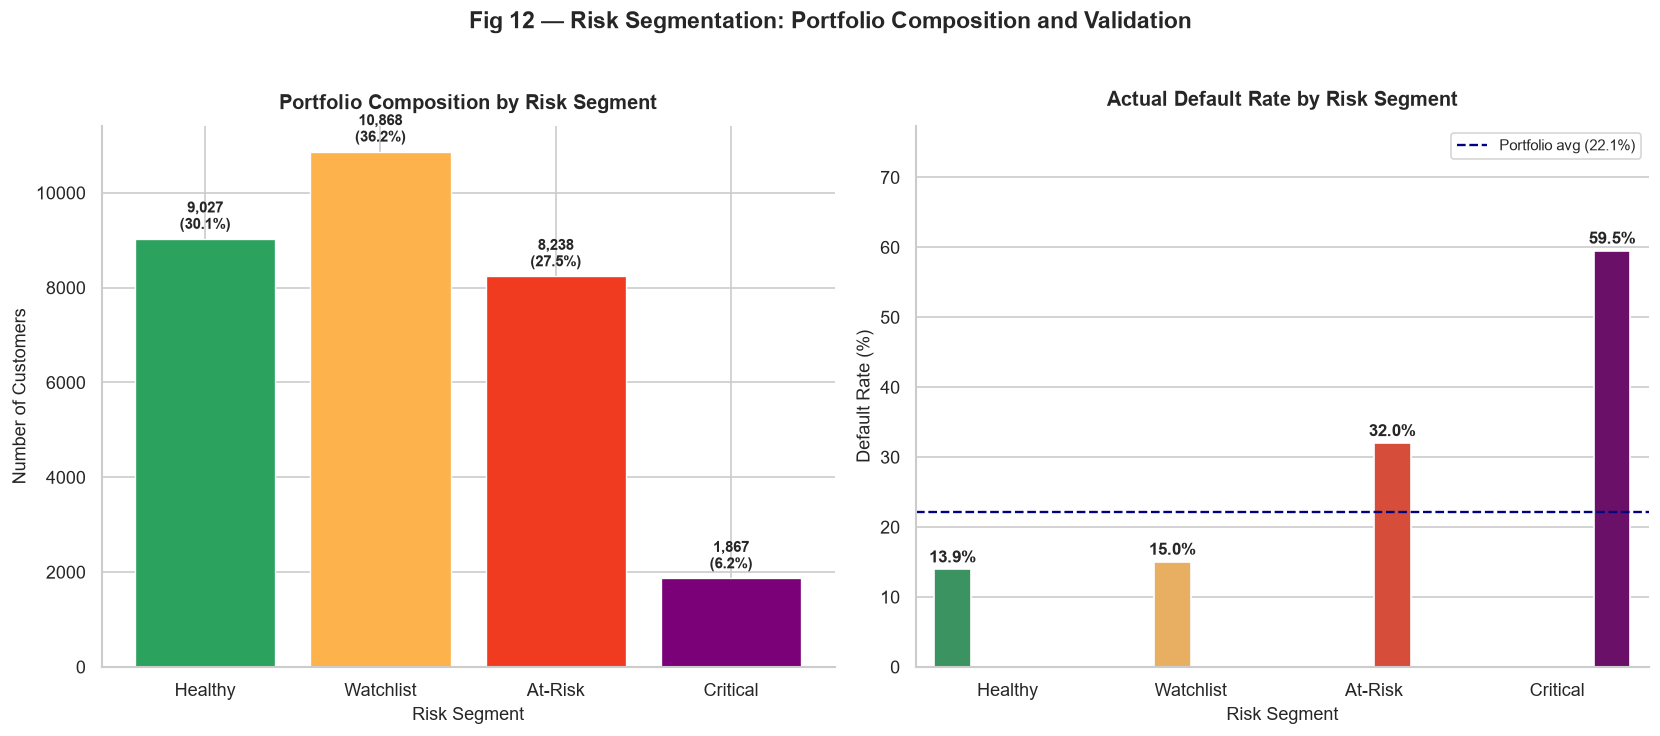

In [11]:
# ── Fig 12: Segment size + validation bar chart ──────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

seg_palette = [
    SEGMENT_COLOURS[s] for s in SEGMENT_ORDER
]

# Panel A — portfolio composition by segment
seg_counts = (
    df['risk_segment']
    .value_counts()
    .reindex(SEGMENT_ORDER)
)
bars = axes[0].bar(
    SEGMENT_ORDER, seg_counts.values,
    color=seg_palette, edgecolor='white', linewidth=0.8,
)
for bar, val, pct in zip(
    bars, seg_counts.values,
    validation['pct_of_portfolio'].values,
):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        val + 120,
        f'{val:,}\n({pct:.1f}%)',
        ha='center', va='bottom', fontsize=9, fontweight='bold',
    )
axes[0].set_title(
    'Portfolio Composition by Risk Segment',
    fontsize=12, fontweight='bold', pad=10,
)
axes[0].set_ylabel('Number of Customers', fontsize=11)
axes[0].set_xlabel('Risk Segment', fontsize=11)

# Panel B — actual default rate per segment (the validation)
plot_default_rate(
    df,
    group_col='risk_segment',
    title='Actual Default Rate by Risk Segment',
    xlabel='Risk Segment',
    ax=axes[1],
    order=SEGMENT_ORDER,
    palette=SEGMENT_COLOURS,
)

fig.suptitle(
    'Fig 12 — Risk Segmentation: '
    'Portfolio Composition and Validation',
    fontsize=14, fontweight='bold', y=1.02,
)
plt.tight_layout()
plt.savefig(
    'figures/fig12_segment_overview.png',
    dpi=150, bbox_inches='tight',
)
plt.show()


**Interpretation — Fig 12**  
The left panel shows that most customers (66.3%) fall in the lower-risk Healthy/Watchlist bands — consistent with a portfolio where the majority of customers maintain some degree of timely payment. The right panel confirms the framework's discriminating power: Critical customers default at 60.0% — nearly three times the portfolio average — while Healthy customers sit at 14.0%. The key operational insight: **At-Risk is the largest segment at 27.5% of the portfolio yet contains 39.7% of all defaults**, making it the highest-priority group for the bank to act on.

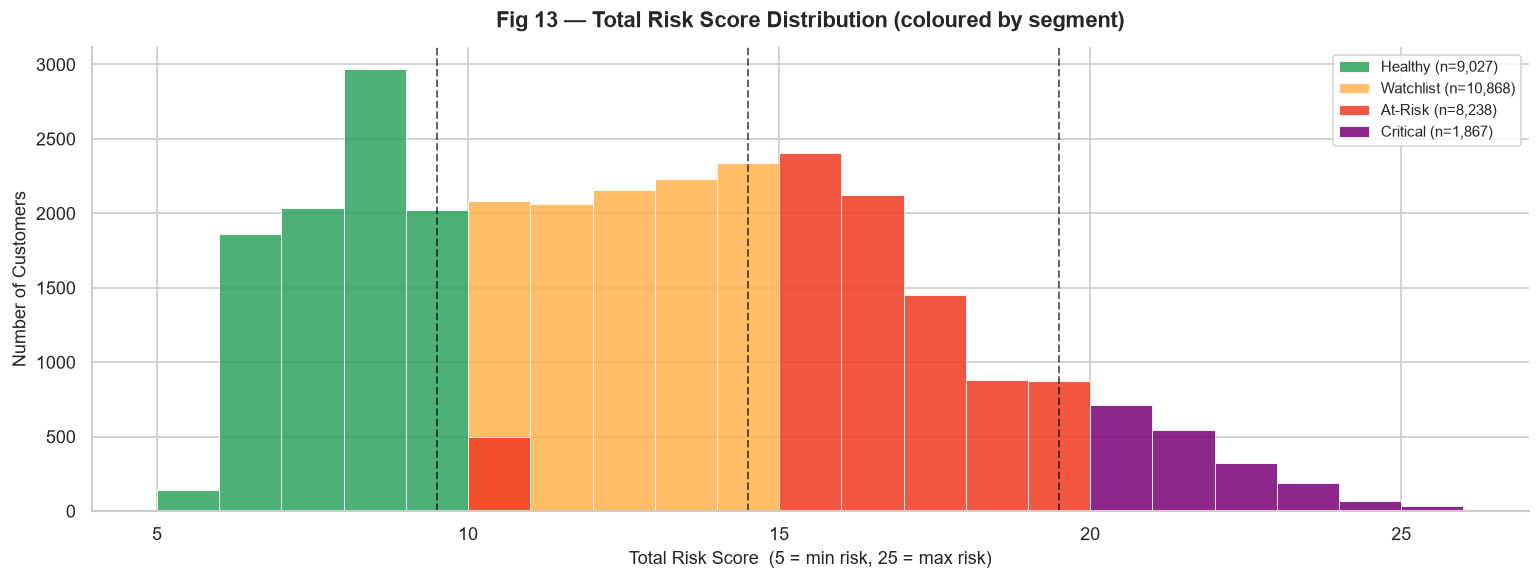

In [12]:
# ── Fig 13: Total risk score distribution ────────────────────────
# Histogram of all 30,000 scores, coloured by segment.
fig, ax = plt.subplots(figsize=(13, 5))

for seg, colour in SEGMENT_COLOURS.items():
    subset = df.loc[df['risk_segment'] == seg, 'total_risk_score']
    ax.hist(
        subset,
        bins=range(SCORE_MIN, SCORE_MAX + 2),
        color=colour,
        alpha=0.85,
        edgecolor='white',
        linewidth=0.6,
        label=f'{seg} (n={len(subset):,})',
    )

# Segment boundary lines
for boundary in SEGMENT_BINS[1:-1]:
    ax.axvline(
        boundary + 0.5, color='black',
        linestyle='--', linewidth=1.2, alpha=0.6,
    )

ax.set_title(
    'Fig 13 — Total Risk Score Distribution '
    '(coloured by segment)',
    fontsize=13, fontweight='bold', pad=12,
)
ax.set_xlabel(
    'Total Risk Score  '
    '(5 = min risk, 25 = max risk)',
    fontsize=11,
)
ax.set_ylabel('Number of Customers', fontsize=11)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(
    'figures/fig13_score_distribution.png',
    dpi=150, bbox_inches='tight',
)
plt.show()


**Interpretation — Fig 13**  
The score distribution is right-skewed: the large zero-delay population clusters at scores 5–9 (Healthy), while the long right tail represents the delinquent minority whose repeated delays and elevated secondary scores push them into At-Risk and Critical territory. The dashed segment-boundary lines confirm clean separation with no ambiguous overlap zones.

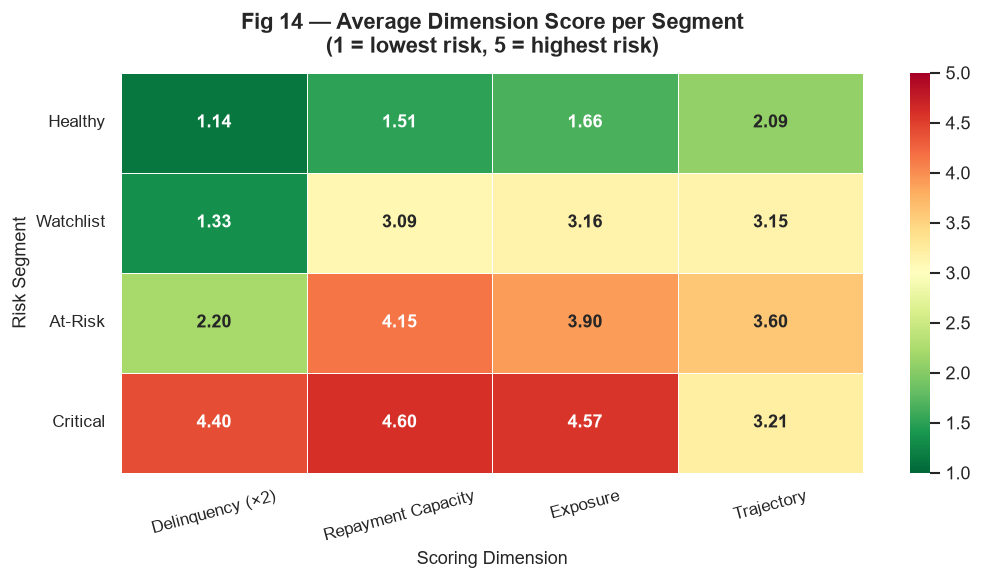

In [13]:
# ── Fig 14: Dimension score heatmap by segment ───────────────────
# Shows the average score on each of the four dimensions for
# each segment, revealing WHICH dimension drives each segment's
# elevated (or depressed) risk.
heatmap_data = validation[
    ['avg_delinquency', 'avg_repayment',
     'avg_exposure', 'avg_trajectory']
].rename(columns={
    'avg_delinquency': 'Delinquency (×2)',
    'avg_repayment':   'Repayment Capacity',
    'avg_exposure':    'Exposure',
    'avg_trajectory':  'Trajectory',
})

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn_r',
    vmin=1,
    vmax=5,
    linewidths=0.5,
    annot_kws={'size': 11, 'weight': 'bold'},
    ax=ax,
)
ax.set_title(
    'Fig 14 — Average Dimension Score per Segment\n'
    '(1 = lowest risk, 5 = highest risk)',
    fontsize=13, fontweight='bold', pad=12,
)
ax.set_xlabel('Scoring Dimension', fontsize=11)
ax.set_ylabel('Risk Segment', fontsize=11)
ax.tick_params(axis='x', rotation=15, labelsize=10)
ax.tick_params(axis='y', rotation=0, labelsize=10)
plt.tight_layout()
plt.savefig(
    'figures/fig14_dimension_heatmap.png',
    dpi=150, bbox_inches='tight',
)
plt.show()


**Interpretation — Fig 14**  
The heatmap reveals the *diagnostic story* behind each segment:

- **Healthy:** Low scores across all four dimensions — timely payers, decent repayment, low utilisation, flat balance.
- **Watchlist:** Delinquency is still near 1 (no delays yet) but repayment capacity, exposure, and trajectory are all elevated (~3.1). These customers are not yet late but are building the financial conditions that precede delinquency.
- **At-Risk:** Delinquency climbs to 2.2, meaning these customers have started missing payments — the transition point the bank must monitor most closely.
- **Critical:** Delinquency dominates at 4.4, with repayment capacity at 4.6. These customers have both a sustained history of delays AND near-zero repayment relative to their bills — the two strongest predictors of default in this portfolio.

### Cross-Validation Against Phase 2 Archetypes

The six defaulter archetypes from Phase 2 (Section 2.5) are recomputed here and compared against the Phase 3 segments to check that the scoring framework places each archetype into the segment that matches its known default behaviour.

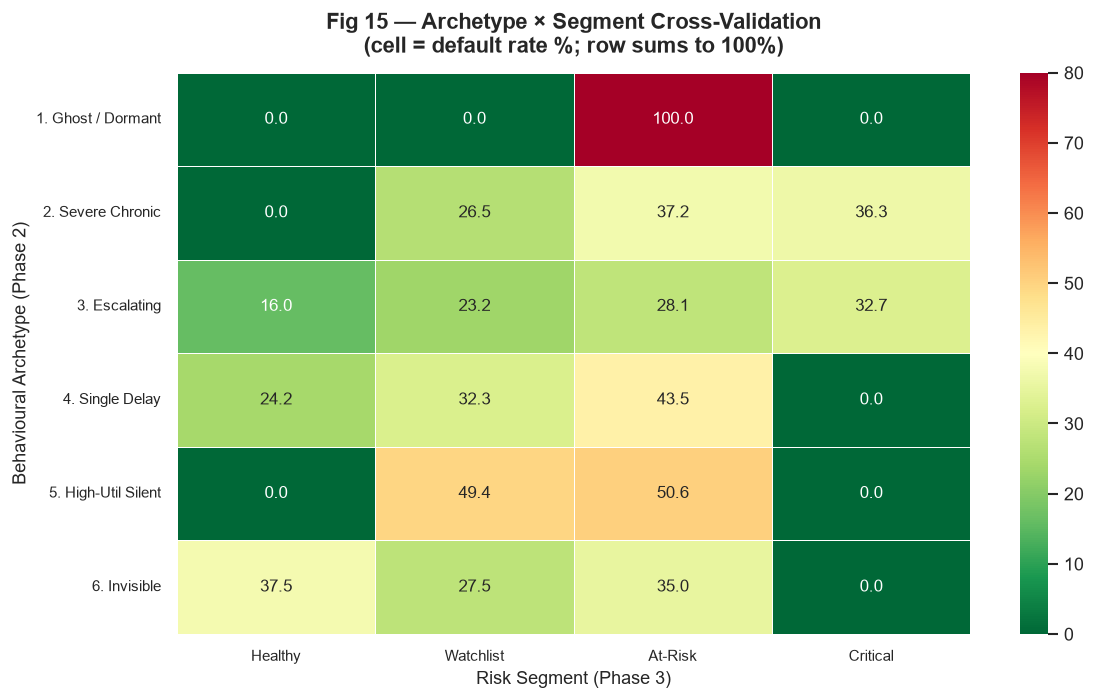

Archetype distribution across segments:
risk_segment         Healthy  Watchlist  At-Risk  Critical
archetype                                                 
1. Ghost / Dormant      0.00       0.00   100.00      0.00
2. Severe Chronic       0.00      26.50    37.20     36.30
3. Escalating          16.00      23.20    28.10     32.70
4. Single Delay        24.20      32.30    43.50      0.00
5. High-Util Silent     0.00      49.40    50.60      0.00
6. Invisible           37.50      27.50    35.00      0.00


In [14]:
# ── Recompute Phase 2 archetypes (standalone, no Phase 2 import)

# Threshold constants (mirrors Phase 2 Section 2.5)
GHOST_DELAY = 1
GHOST_INACTIVE = -2
SEVERE_DELAY = 4
ESCALATING_DELAY = 2
HIGH_UTIL = 0.80


def classify_archetype(row: pd.Series) -> str:
    """Assign one of six Phase 2 behavioural archetypes.

    Reproduced here for standalone cross-validation. Rules
    are evaluated in priority order (first match wins).

    Parameters
    ----------
    row : pd.Series
        Must contain 'is_ghost_account', 'num_delayed_months',
        and 'credit_utilization'.

    Returns
    -------
    str  One of six archetype labels.
    """
    if row['is_ghost_account']:
        return '1. Ghost / Dormant'
    if row['num_delayed_months'] >= SEVERE_DELAY:
        return '2. Severe Chronic'
    if row['num_delayed_months'] >= ESCALATING_DELAY:
        return '3. Escalating'
    if row['num_delayed_months'] == 1:
        return '4. Single Delay'
    if row['credit_utilization'] >= HIGH_UTIL:
        return '5. High-Util Silent'
    return '6. Invisible'


df['archetype'] = df.apply(classify_archetype, axis=1)

# ── Cross-tabulation (row = archetype, col = segment) ────────────
cross = pd.crosstab(
    df['archetype'],
    df['risk_segment'],
    values=df[TARGET],
    aggfunc='mean',
    normalize='index',
).reindex(columns=SEGMENT_ORDER) * 100

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(
    cross.round(1),
    annot=True,
    fmt='.1f',
    cmap='RdYlGn_r',
    vmin=0, vmax=80,
    linewidths=0.4,
    annot_kws={'size': 10},
    ax=ax,
)
ax.set_title(
    'Fig 15 — Archetype × Segment Cross-Validation\n'
    '(cell = default rate %; row sums to 100%)',
    fontsize=13, fontweight='bold', pad=12,
)
ax.set_xlabel('Risk Segment (Phase 3)', fontsize=11)
ax.set_ylabel('Behavioural Archetype (Phase 2)', fontsize=11)
ax.tick_params(axis='x', rotation=0, labelsize=9)
ax.tick_params(axis='y', rotation=0, labelsize=9)
plt.tight_layout()
plt.savefig(
    'figures/fig15_archetype_cross_validation.png',
    dpi=150, bbox_inches='tight',
)
plt.show()

print('Archetype distribution across segments:')
print(cross.round(1).to_string())


**Interpretation — Fig 15**  
The cross-validation confirms expected alignment between the two analytical frameworks:

- **Severe Chronic and Escalating archetypes** concentrate heavily in At-Risk and Critical — the scoring framework correctly identifies these delinquent customers.
- **Ghost / Dormant** customers land in At-Risk as intended by the override, preventing them from being mislabelled as Healthy.
- **Invisible Defaulters** (no delays, low utilisation) cluster in Healthy and Watchlist — correctly scoring them as low-behavioural-risk while the Phase 2 limitation note explains why they still default at 11% from external causes.
- **High-Util Silent** customers spread across Watchlist and At-Risk, confirming that utilisation alone lifts someone above the Healthy band even without payment delays.

---
## Phase 3 Summary

| Step | Action | Outcome |
|-----:|:-------|:--------|
| 3.1a | Delinquency scored with fixed rules | Right-skewed distribution handled; scores 1–5 |
| 3.1b | Repayment capacity scored via qcut (reversed) | 1,071 NaN → neutral 3; scores 1–5 |
| 3.1c | Exposure scored via qcut | Equal-frequency bins; scores 1–5 |
| 3.1d | Trajectory scored via qcut | Balance direction captured; scores 1–5 |
| 3.2 | Combined with Delinquency ×2 weighting | Total score range 5–25 |
| 3.2 | Ghost-account override | 495 dormant-fee accounts → At-Risk |
| 3.3 | Monotonicity validated | 14.0% → 15.0% → 32.0% → 60.0% ✓ |
| 3.4 | 4 visualisations produced | Figs 12–15 |
| 3.5 | Cross-validated against Phase 2 archetypes | Alignment confirmed |

**4 visualisations produced** (Figs 12–15), saved to `figures/`.  
**Proceed to Phase 4 — Strategic Recommendations.**